# Communities

Do MPs group by party or by topic? Louvain vs label propagation, then what's inside each community.

In [9]:
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd
from networkx.algorithms import community as nxcom

DATA_DIR = Path("data")
RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(exist_ok=True)

nodes = pd.read_csv(DATA_DIR / "nodes.csv")
edges = pd.read_csv(DATA_DIR / "edges.csv")
speeches = pd.read_csv(DATA_DIR / "speeches.csv")
names = dict(zip(nodes["id"], nodes["name"]))
PERIODS = ["sunak", "starmer", "burnham"]   # Prime Minister in office
party = {p: dict(zip(nodes["id"], nodes[f"party_{p}"])) for p in PERIODS}

SEED = 42

### Undirected version

For communities the order doesn't matter, so w(A,B) = w(A->B) + w(B->A).

In [10]:
def undirected_graph(period):
    G = nx.Graph()
    period_edges = edges[edges["period"] == period]
    for s, t, w in period_edges[["source", "target", "weight"]].itertuples(index=False):
        if G.has_edge(s, t):
            G[s][t]["weight"] += w
        else:
            G.add_edge(s, t, weight=w)
    nx.set_node_attributes(G, {n: party[period][n] for n in G}, "party")
    return G

graphs = {p: undirected_graph(p) for p in PERIODS}
for p, G in graphs.items():
    print(p, G.number_of_nodes(), "nodes", G.number_of_edges(), "undirected edges")

sunak 638 nodes 20880 undirected edges
starmer 643 nodes 34701 undirected edges
burnham 605 nodes 4715 undirected edges


### Louvain

resolution 1, seed 42. Ran it with 20 seeds to make sure the result is stable.

In [11]:
louvain, stability = {}, []
for p, G in graphs.items():
    louvain[p] = nxcom.louvain_communities(G, weight="weight", resolution=1, seed=SEED)
    for s in range(20):
        parts = nxcom.louvain_communities(G, weight="weight", resolution=1, seed=s)
        stability.append({"period": p, "seed": s, "communities": len(parts),
                          "modularity": nxcom.modularity(G, parts, weight="weight")})

stability = pd.DataFrame(stability)
stability.groupby("period").agg(
    communities_min=("communities", "min"), communities_max=("communities", "max"),
    modularity_min=("modularity", "min"), modularity_max=("modularity", "max"),
).round(3)

,communities_min,communities_max,modularity_min,modularity_max
period,,,,
burnham,11,15,0.272,0.281
starmer,7,10,0.158,0.163
sunak,8,11,0.184,0.188


### Comparison

Louvain vs label propagation, and parties used as the groups to compare against.

In [12]:
rows = []
lpa = {}
for p, G in graphs.items():
    lpa[p] = list(nxcom.asyn_lpa_communities(G, weight="weight", seed=SEED))
    by_party = {}
    for n in G:
        by_party.setdefault(G.nodes[n]["party"], set()).add(n)
    for method, parts in [("Louvain", louvain[p]), ("Label propagation", lpa[p]), ("Party split", list(by_party.values()))]:
        sizes = sorted((len(c) for c in parts), reverse=True)
        rows.append({"period": p, "method": method, "communities": len(parts),
                     "largest 5 sizes": sizes[:5],
                     "modularity": round(nxcom.modularity(G, parts, weight="weight"), 3)})

comparison = pd.DataFrame(rows)
comparison.to_csv(RESULTS_DIR / "communities_comparison.csv", index=False)
comparison

,period,method,communities,largest 5 sizes,modularity
0,sunak,Louvain,8,"[129, 126, 125, 107, 66]",0.189
1,sunak,Label propagation,1,[638],0.000
2,sunak,Party split,14,"[344, 201, 43, 15, 15]",-0.074
3,starmer,Louvain,10,"[157, 113, 73, 73, 70]",0.161
4,starmer,Label propagation,1,[643],0.000
5,starmer,Party split,15,"[406, 116, 72, 10, 10]",-0.049
6,burnham,Louvain,12,"[92, 77, 57, 54, 52]",0.279
7,burnham,Label propagation,2,"[590, 15]",0.043
8,burnham,Party split,15,"[374, 111, 71, 12, 8]",-0.055


Label propagation ends up with basically one big group: the graph is too dense and a few MPs are linked to almost everyone. Parties as groups give a negative modularity.

### Parties in each community

In [13]:
def community_table(p):
    rows = []
    for i, c in enumerate(sorted(louvain[p], key=len, reverse=True)):
        for n in c:
            rows.append({"period": p, "community": i + 1, "id": n, "name": names[n], "party": party[p][n]})
    return pd.DataFrame(rows)

members = pd.concat([community_table(p) for p in PERIODS])
members.to_csv(RESULTS_DIR / "communities_mps.csv", index=False)

for p in PERIODS:
    m = members[members["period"] == p]
    mix = pd.crosstab(m["community"], m["party"], normalize="index").mul(100).round(0)
    mix = mix.loc[:, mix.max() >= 5]  # hide parties under 5% everywhere
    mix.insert(0, "MPs", m.groupby("community").size())
    print(f"--- {p}: party share (%) in each community")
    print(mix.to_string())
    print()

--- sunak: party share (%) in each community
party      MPs  Alba  Conservative   DUP  Independent  Labour  Liberal Democrat  Scottish National Party  Social Democratic and Labour Party
community                                                                                                                                   
1          129   0.0          59.0   0.0          3.0    32.0               2.0                      4.0                                 0.0
2          126   0.0          48.0   0.0          3.0    40.0               2.0                      5.0                                 0.0
3          125   1.0          48.0   0.0          5.0    27.0               2.0                     14.0                                 0.0
4          107   0.0          56.0   0.0          0.0    35.0               4.0                      6.0                                 0.0
5           66   0.0          62.0   0.0          0.0    27.0               2.0                      8.0     

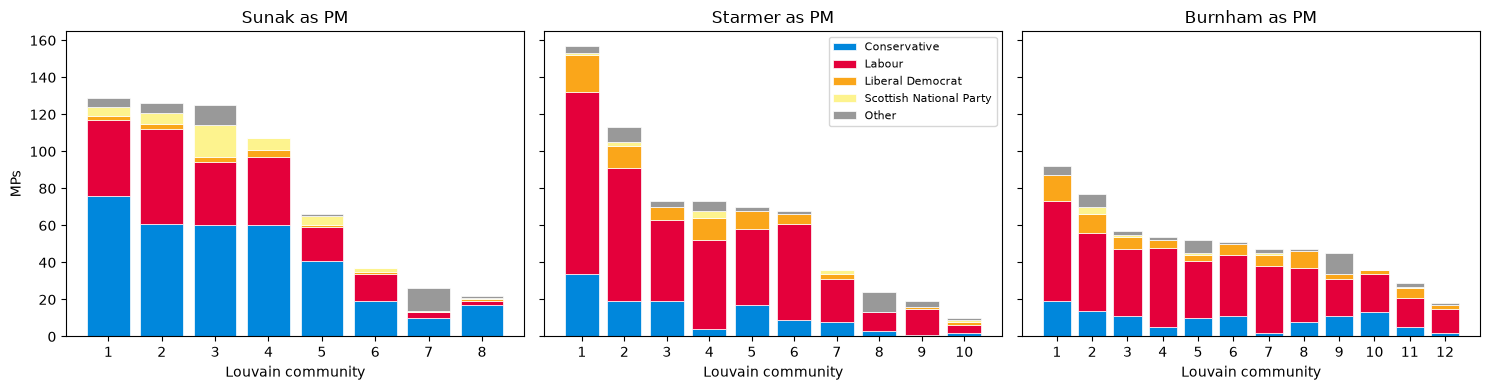

In [14]:
MAIN = ["Conservative", "Labour", "Liberal Democrat", "Scottish National Party"]
colours = {"Conservative": "#0087DC", "Labour": "#E4003B", "Liberal Democrat": "#FAA61A",
           "Scottish National Party": "#FDF38E", "Other": "#999999"}

fig, axes = plt.subplots(1, len(PERIODS), figsize=(15, 4), sharey=True)
for ax, p in zip(axes, PERIODS):
    m = members[members["period"] == p].assign(group=lambda d: d["party"].where(d["party"].isin(MAIN), "Other"))
    counts = pd.crosstab(m["community"], m["group"]).reindex(columns=MAIN + ["Other"], fill_value=0)
    bottom = None
    for g in counts.columns:
        ax.bar(counts.index.astype(str), counts[g], bottom=bottom, color=colours[g], label=g, edgecolor="white", linewidth=0.5)
        bottom = counts[g] if bottom is None else bottom + counts[g]
    ax.set_title(f"{p.capitalize()} as PM")
    ax.set_xlabel("Louvain community")
axes[0].set_ylabel("MPs")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "communities_party_mix.png", dpi=200)
plt.show()

### Topics of each community

Topics a community talks about more than the rest of the House (lift = their share / overall share, min 30 speeches).

In [15]:
def topics(p, k=5, min_speeches=30):
    s = speeches[speeches["period"] == p].dropna(subset=["major_heading"])
    overall = s["major_heading"].value_counts(normalize=True)
    m = members[members["period"] == p][["id", "community"]]
    s = s.merge(m, left_on="person_id", right_on="id")
    out = []
    for c, grp in s.groupby("community"):
        counts = grp["major_heading"].value_counts()
        share = counts / counts.sum()
        lift = (share / overall.reindex(share.index)).where(counts >= min_speeches).dropna()
        best = lift.sort_values(ascending=False).head(k)
        out.append({"community": c, "MPs": m[m["community"] == c].shape[0],
                    "top topics (lift)": "; ".join(f"{t} ({v:.1f})" for t, v in best.items())})
    return pd.DataFrame(out)

for p in PERIODS:
    print(f"--- {p}")
    t = topics(p)
    t.to_csv(RESULTS_DIR / f"communities_topics_{p}.csv", index=False)
    for _, r in t.iterrows():
        print(f"{r['community']} ({r['MPs']} MPs): {r['top topics (lift)']}")
    print()

--- sunak
1 (129 MPs): Automated Vehicles Bill [Lords] (4.2); Zoological Society of London (Leases) Bill (4.1); Channel 4 (3.8); Football Governance White Paper (3.7); Gambling Act Review White Paper (3.6)
2 (126 MPs): Overseas Territories (4.6); Situation in the Red Sea (4.2); Global Military Operations (4.1); Defence Personnel Data Breach (4.0); LGBT Veterans Independent Review (4.0)
3 (125 MPs): Cost of Living Committee (5.0); Constitutional Law (5.0); Cost of Living (4.8); Work Capability Assessment Consultation (4.6); Social Security (Additional Payments) (No. 2) Bill (4.5)
4 (107 MPs): Lifelong Learning (Higher Education Fee Limits) Bill (5.4); NHS Strikes (4.9); Under-age Vaping (4.9); Voter ID (4.7); Funded Childcare (4.7)
5 (66 MPs): Windrush Lessons Learned Review: Implementation of Recommendations (6.4); Illegal Migration Bill (6.4); Illegal Migration Bill: Economic Impact Assessment (6.1); Knowsley Incident (6.0); Rwanda Plan Cost and Asylum System (6.0)
6 (37 MPs): Post Of

### Main MPs in each community

In [16]:
for p in PERIODS:
    G = graphs[p]
    print(f"--- {p}")
    for i, c in enumerate(sorted(louvain[p], key=len, reverse=True)):
        inner = G.subgraph(c).degree(weight="weight")
        top = sorted(inner, key=lambda x: -x[1])[:5]
        print(f"{i + 1}: " + ", ".join(f"{names[n]} ({party[p][n]})" for n, _ in top))
    print()

--- sunak
1: Penny Mordaunt (Conservative), Huw Merriman (Conservative), Mark Harper (Conservative), Lucy Frazer (Conservative), Therese Coffey (Conservative)
2: Andrew Mitchell (Conservative), James Cleverly (Conservative), Grant Shapps (Conservative), Leo Docherty (Conservative), Alex Chalk (Conservative)
3: Graham Stuart (Conservative), Mel Stride (Conservative), Oliver Dowden (Conservative), David Davies (Conservative), Jeremy Hunt (Conservative)
4: Steve Barclay (Conservative), Gillian Keegan (Conservative), Victoria Atkins (Conservative), Lee Rowley (Conservative), Michael Gove (Conservative)
5: Robert Jenrick (Conservative), Suella Braverman (Conservative), Chris Philp (Conservative), Alison Thewliss (Scottish National Party), Yvette Cooper (Labour)
6: Kevin Hollinrake (Conservative), Kevan Jones (Labour), Kemi Badenoch (Conservative), Nusrat Ghani (Conservative), Liam Byrne (Labour)
7: Chris Heaton-Harris (Conservative), Steven Baker (Conservative), Jim Shannon (DUP), Jeffrey M